## Cortical Nuclear data

# 0. Data-preparation readiness checklist

## Scientific purpose and provenance

- [x] Is the biological question and prediction task stated clearly?
  
  Yes, as per the paper, the aim is to identify subsets of proteins that are discriminant between the classes.
- [x] Is the unit of observation clear (for example, patient, tissue, cell, mouse, or technical measurement)?
    
  The file with dataset lacks information, however it's described in the paper it was taken from (https://www.semanticscholar.org/reader/5c5754b02a4f2f36ccf8cdda78059cdb19860532), as well as in the dataset download source itself (https://archive.ics.uci.edu/dataset/342/mice+protein+expression).
- [x] Do I know where the data came from, how they were generated, and under which license or access conditions they may be used?
  
  Yes, licence and source are described via link https://archive.ics.uci.edu/dataset/342/mice+protein+expression.
- [x] Have I recorded the data version, processing history, and transformations already applied?
  
  We have a note on Missing Values presence per feature. Also we have a statement that measurements are independent.

## Table shape and identifiers

- [x] Is the table tidy: one observation per row, one variable per column, and one value per cell?
  
  Per row: 1 measurement of the 77 proteins from 1 mouse, taken 15 times
- [x] If the original assay has features in rows and samples in columns, have I transposed it into the format expected by the analysis tool?
  
  No, the mice (samples) are in rows, prots are the colums, everything's as expected.
- [x] Are row names, column names, and identifiers clear, unique, stable, and free from accidental index columns?
  
  Yes
- [x] Can every feature and observation be traced back to its source?

  Yes
- [x] Are the feature matrix and metadata aligned by an explicit identifier rather than by row order?
  Yes, we have `Genotype`, `Treatment`, `Behavior` per mouse ID.


## Types, values, and measurement meaning

- [ ] Are numerical, categorical, ordinal, text, date, and identifier columns correctly classified?
- [ ] Are units, scales, encodings, reference categories, and detection limits understood?
- [ ] Have I checked impossible values, inconsistent labels, unexpected categories, constant features, and extreme values?
- [ ] Are normalization, scaling, log transformation, and batch-correction steps documented?

## Missing values

- [ ] Have I detected missing values using the dataset's actual missing-value representations, not only `NaN`?
- [ ] Have I measured missingness by row, column, group, and relevant batch or time variable?
- [ ] Do I know whether missingness is structural, technical, or plausibly related to the biology or target?
- [ ] Have I justified whether to retain, remove, or impute missing values?
- [ ] If imputing, will the imputer be fitted on training data only and then applied to validation/test data?

## Replicates, dependence, and grouping

- [ ] Have I checked for exact duplicates and near-duplicate observations?
- [ ] Are observations biological replicates, technical replicates, repeated measurements, pseudo-replicates, or independent samples?
- [ ] Is the independent biological unit identified by a grouping variable?
- [ ] Will all related observations and their derivatives remain in the same train/validation/test split?
- [ ] If I created augmented or synthetic observations, is their provenance recorded and reproducible?

## Target, leakage, and study design

- [ ] Is the target defined before modelling, with its classes or values checked for balance and validity?
- [ ] Have I excluded identifiers, post-outcome variables, duplicated target information, and other leakage sources from the features?
- [ ] Have I identified batch, site, plate, subject, cohort, treatment, sex, age, time, or other possible confounders?
- [ ] Have I checked whether the target is associated with a technical or grouping variable?
- [ ] Does the planned split represent the biological generalization question?

## Reproducibility and decision record

- [ ] Are random seeds, software versions, file names, and input/output shapes recorded?
- [ ] Are all preprocessing steps placed in a reproducible pipeline?
- [ ] Have I recorded unresolved data-quality concerns and the decisions made about them?
- [ ] Can another person explain what each row, column, feature, target, and grouping variable means?

## Short preparation summary

Before modelling, write down:

- biological unit: I guess it's 1 mouse with 77 prots measured: 15 rows each (same mouse ID before the underscore 309_1 .. 309_15).
- number of observations and features: 
  - observations = 1080 rows = 72 mice * 15 measurements
  - 77 features = 77 protein-expression measurements
- target and feature definition: 
  - target: genotype (control vs. trisomic) — a direct, two-class biological question. We do not use `class`, because it is constructed from `Genotype`, `Treatment`, and `Behavior` combined (confirmed in Section C.7 below), so it mixes three design factors into one label
  - feature definition: protein-expression measurements
- missing-value decision: median imputation
- replicate/grouping decision: each mouse's 15 repeated trials are grouped by mouse_id (the alphanumeric prefix of mouse_id); GroupShuffleSplit keeps every mouse entirely in either train or test, so no leakage happens.
- main confounder or possible leakage source: class (Genotype + Treatment + Behavior) must not be used as a feature when predicting Genotype.
- train/test split and why it is appropriate: GroupShuffleSplit (75/25) grouped on mouse_id, because the scientific question is generalization to new mice, not repeated measurements.
- remaining concerns: 
  - dataset imbalance: t-CS-s has only 7 mice vs. 9–10 elsewhere, missingness rate varies by class also
  - the 3 J-mice noted above show much larger within-class differences than other mice. Looks like batch effect, nit biology.
  - several protein pairs are highly correlated (>0.9)
  - a negative value for 1 mouse (RRP1_N)
  - GroupShuffleSplit does not stratify by class, so per-class counts in train/test are not guaranteed to be balanced


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

DATA = Path(".")
RANDOM_STATE = 100926

In [3]:
mice_raw = pd.read_excel(DATA / "Data_Cortex_Nuclear.xls")
metadata_cols = ["MouseID", "Genotype", "Treatment", "Behavior", "class"]
protein_cols = [c for c in mice_raw.columns if c not in metadata_cols]

print("Mice raw:", mice_raw.shape)
mice_raw.head()
print("Metadata columns:", metadata_cols)
print("Protein-expression columns:", len(protein_cols))

Mice raw: (1080, 82)
Metadata columns: ['MouseID', 'Genotype', 'Treatment', 'Behavior', 'class']
Protein-expression columns: 77


In [5]:
mice_raw.head()

,MouseID,DYRK1A_N,ITSN1_N,BDNF_N,NR1_N,NR2A_N,pAKT_N,pBRAF_N,pCAMKII_N,pCREB_N,...,pCFOS_N,SYP_N,H3AcK18_N,EGR1_N,H3MeK4_N,CaNA_N,Genotype,Treatment,Behavior,class
0,309_1,0.503644,0.747193,0.430175,2.816329,5.990152,0.218830,0.177565,2.373744,0.232224,...,0.108336,0.427099,0.114783,0.131790,0.128186,1.675652,Control,Memantine,C/S,c-CS-m
1,309_2,0.514617,0.689064,0.411770,2.789514,5.685038,0.211636,0.172817,2.292150,0.226972,...,0.104315,0.441581,0.111974,0.135103,0.131119,1.743610,Control,Memantine,C/S,c-CS-m
2,309_3,0.509183,0.730247,0.418309,2.687201,5.622059,0.209011,0.175722,2.283337,0.230247,...,0.106219,0.435777,0.111883,0.133362,0.127431,1.926427,Control,Memantine,C/S,c-CS-m
3,309_4,0.442107,0.617076,0.358626,2.466947,4.979503,0.222886,0.176463,2.152301,0.207004,...,0.111262,0.391691,0.130405,0.147444,0.146901,1.700563,Control,Memantine,C/S,c-CS-m
4,309_5,0.434940,0.617430,0.358802,2.365785,4.718679,0.213106,0.173627,2.134014,0.192158,...,0.110694,0.434154,0.118481,0.140314,0.148380,1.839730,Control,Memantine,C/S,c-CS-m


## B. EDA and tidy-data assessment
### B.1 Dimensions and types

In [6]:
mice_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1080 entries, 0 to 1079
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   MouseID          1080 non-null   str    
 1   DYRK1A_N         1077 non-null   float64
 2   ITSN1_N          1077 non-null   float64
 3   BDNF_N           1077 non-null   float64
 4   NR1_N            1077 non-null   float64
 5   NR2A_N           1077 non-null   float64
 6   pAKT_N           1077 non-null   float64
 7   pBRAF_N          1077 non-null   float64
 8   pCAMKII_N        1077 non-null   float64
 9   pCREB_N          1077 non-null   float64
 10  pELK_N           1077 non-null   float64
 11  pERK_N           1077 non-null   float64
 12  pJNK_N           1077 non-null   float64
 13  PKCA_N           1077 non-null   float64
 14  pMEK_N           1077 non-null   float64
 15  pNR1_N           1077 non-null   float64
 16  pNR2A_N          1077 non-null   float64
 17  pNR2B_N          1077 non

### B.2 Distribution of experimental factors

In [7]:
for col in ["Genotype", "Treatment", "Behavior", "class"]:
    print(mice_raw[col].value_counts())
    print()

Genotype
Control    570
Ts65Dn     510
Name: count, dtype: int64

Treatment
Memantine    570
Saline       510
Name: count, dtype: int64

Behavior
S/C    555
C/S    525
Name: count, dtype: int64

class
c-CS-m    150
c-SC-m    150
c-CS-s    135
c-SC-s    135
t-CS-m    135
t-SC-m    135
t-SC-s    135
t-CS-s    105
Name: count, dtype: int64



### B.3 Rows and mice per group

Derive the biological samples from MouseID (prefix).

In [9]:
mouse_id = mice_raw["MouseID"].str.split("_").str[0]
mice_raw = mice_raw.assign(mouse_id=mouse_id)

print("Rows:", mice_raw.shape[0])
print("Unique mice:", mice_raw["mouse_id"].nunique())
print("Rows per mouse:")
mice_raw.groupby("mouse_id").size().describe()

Rows: 1080
Unique mice: 72
Rows per mouse:


count    72.0
mean     15.0
std       0.0
min      15.0
25%      15.0
50%      15.0
75%      15.0
max      15.0
dtype: float64

In [10]:
mice_per_class = mice_raw.groupby("class")["mouse_id"].nunique()
rows_per_class = mice_raw["class"].value_counts()

pd.DataFrame({"mice": mice_per_class, "rows": rows_per_class})

,mice,rows
class,,
c-CS-m,10,150
c-CS-s,9,135
c-SC-m,10,150
c-SC-s,9,135
t-CS-m,9,135
t-CS-s,7,105
t-SC-m,9,135
t-SC-s,9,135


## B.4 Exploration plots

**Plot 1** does a protein differ by genotype? if trisomy is associated with a shift in protein expression.

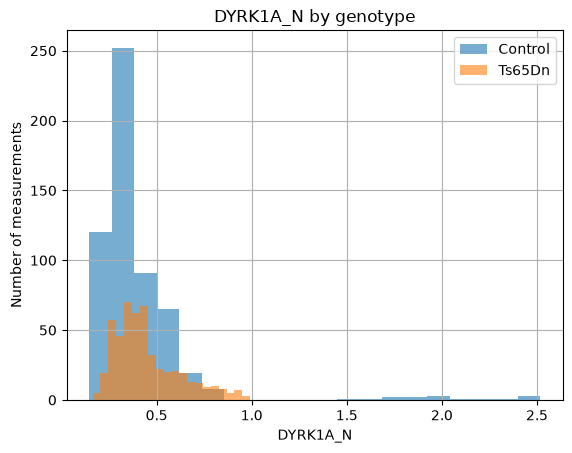

In [11]:
example_protein = protein_cols[0]

for genotype, group in mice_raw.groupby("Genotype"):
    group[example_protein].hist(bins=20, alpha=0.6, label=genotype)

plt.xlabel(example_protein)
plt.ylabel("Number of measurements")
plt.title(f"{example_protein} by genotype")
plt.legend()
plt.show()

**Plot 2** PCA by genotype - if genotype is the dominant (over treatment and behavior) source of variation in the proteins per samples.

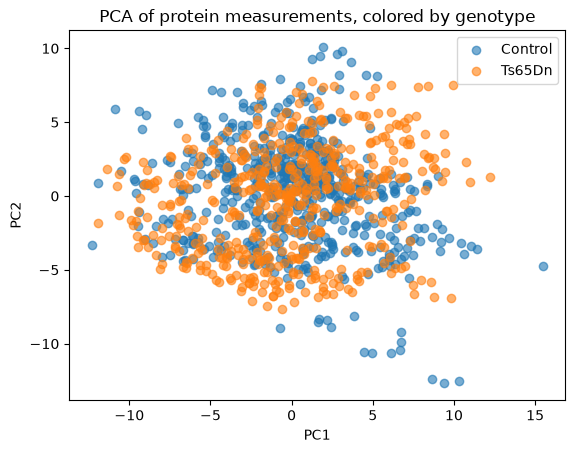

In [12]:
X_vis = StandardScaler().fit_transform(mice_raw[protein_cols].fillna(mice_raw[protein_cols].median()))

pca_vis = PCA(n_components=2)
coords_vis = pca_vis.fit_transform(X_vis)

vis_df = pd.DataFrame({
    "PC1": coords_vis[:, 0],
    "PC2": coords_vis[:, 1],
    "Genotype": mice_raw["Genotype"].values
})

for genotype, group in vis_df.groupby("Genotype"):
    plt.scatter(group["PC1"], group["PC2"], label=genotype, alpha=0.6)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of protein measurements, colored by genotype")
plt.legend()
plt.show()

**Plot 3** how many measurements is present per each mouse? addresses the repeated-measures.

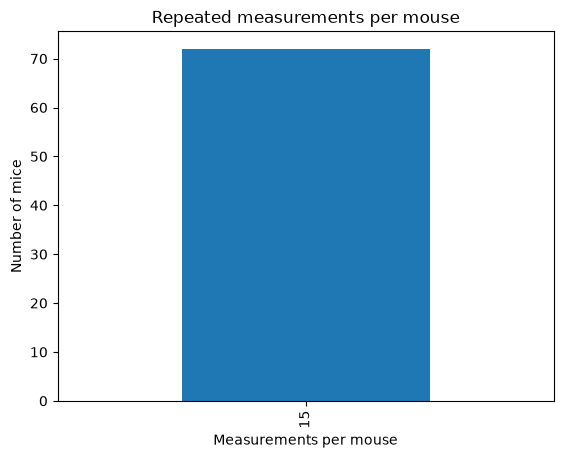

In [13]:
mice_raw.groupby("mouse_id").size().value_counts().sort_index().plot(kind="bar")
plt.xlabel("Measurements per mouse")
plt.ylabel("Number of mice")
plt.title("Repeated measurements per mouse")
plt.show()

## C. Diagnostics
### C.1 Missing values

In [14]:
missing_by_column = mice_raw[protein_cols].isna().sum()
missing_by_row = mice_raw[protein_cols].isna().sum(axis=1)

print("Total missing protein values:", int(missing_by_column.sum()))
print("Proteins with at least one missing value:", int((missing_by_column > 0).sum()))
print("Rows with at least one missing value:", int((missing_by_row > 0).sum()))

missing_by_column[missing_by_column > 0].sort_values(ascending=False).head(8)

Total missing protein values: 1396
Proteins with at least one missing value: 49
Rows with at least one missing value: 528


BCL2_N        285
H3MeK4_N      270
BAD_N         213
EGR1_N        210
H3AcK18_N     180
pCFOS_N        75
ELK_N          18
Bcatenin_N     18
dtype: int64

Missingness is not evenly spread across classes for the most affected proteins, which suggests it is not purely random.

In [15]:
top_missing = missing_by_column.sort_values(ascending=False).head(3).index

for protein in top_missing:
    print(protein)
    print(mice_raw.assign(missing=mice_raw[protein].isna()).groupby("class")["missing"].mean().round(2))
    print()

BCL2_N
class
c-CS-m    0.20
c-CS-s    0.22
c-SC-m    0.50
c-SC-s    0.22
t-CS-m    0.11
t-CS-s    0.14
t-SC-m    0.33
t-SC-s    0.33
Name: missing, dtype: float64

H3MeK4_N
class
c-CS-m    0.40
c-CS-s    0.33
c-SC-m    0.40
c-SC-s    0.22
t-CS-m    0.22
t-CS-s    0.00
t-SC-m    0.33
t-SC-s    0.00
Name: missing, dtype: float64

BAD_N
class
c-CS-m    0.20
c-CS-s    0.33
c-SC-m    0.32
c-SC-s    0.11
t-CS-m    0.22
t-CS-s    0.00
t-SC-m    0.33
t-SC-s    0.00
Name: missing, dtype: float64



### C.2 Duplicates

In [16]:
print("Duplicate MouseIDs:", mice_raw["MouseID"].duplicated().sum())
print("Duplicate full rows:", mice_raw.duplicated().sum())

Duplicate MouseIDs: 0
Duplicate full rows: 0


### C.3 Expected number of repeated measurements

In [17]:
rows_per_mouse = mice_raw.groupby("mouse_id").size()
print("Mice without exactly 15 measurements:", (rows_per_mouse != 15).sum())

Mice without exactly 15 measurements: 0


### C.4 Unusual categories

In [18]:
for col in ["Genotype", "Treatment", "Behavior", "class"]:
    print(col, sorted(mice_raw[col].unique()))

Genotype ['Control', 'Ts65Dn']
Treatment ['Memantine', 'Saline']
Behavior ['C/S', 'S/C']
class ['c-CS-m', 'c-CS-s', 'c-SC-m', 'c-SC-s', 't-CS-m', 't-CS-s', 't-SC-m', 't-SC-s']


### C.5 Implausible values

Protein-expression intensities are not expected to be negative.

In [19]:
negative_counts = (mice_raw[protein_cols] < 0).sum()
print("Proteins with negative values:", (negative_counts > 0).sum())
mice_raw[protein_cols][mice_raw[protein_cols] < 0].stack()

Proteins with negative values: 1


0     DYRK1A_N    NaN
      ITSN1_N     NaN
      BDNF_N      NaN
      NR1_N       NaN
      NR2A_N      NaN
                   ..
1079  SYP_N       NaN
      H3AcK18_N   NaN
      EGR1_N      NaN
      H3MeK4_N    NaN
      CaNA_N      NaN
Length: 83160, dtype: float64

### C.6 Highly correlated proteins

In [21]:
corr = mice_raw[protein_cols].corr().abs()
corr_pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()

print("Protein pairs with |correlation| > 0.9:", (corr_pairs > 0.9).sum())
corr_pairs[corr_pairs > 0.9].sort_values(ascending=False).head(10)

Protein pairs with |correlation| > 0.9: 10


ARC_N     pS6_N         1.000000
DYRK1A_N  BRAF_N        0.959578
          ITSN1_N       0.959512
NR1_N     pNR1_N        0.947872
DYRK1A_N  pERK_N        0.945719
pERK_N    BRAF_N        0.926984
ITSN1_N   BRAF_N        0.917608
NR1_N     Bcatenin_N    0.914610
pNR1_N    pNR2B_N       0.906504
ITSN1_N   pERK_N        0.906289
dtype: float64

### C.7 Is any candidate predictor a deterministic part of the target?

In [22]:
combo = mice_raw["Genotype"] + "|" + mice_raw["Treatment"] + "|" + mice_raw["Behavior"]
classes_per_combo = mice_raw.groupby(combo)["class"].nunique()

print("Genotype/Treatment/Behavior combinations:", classes_per_combo.shape[0])
print("Combinations mapping to more than one class:", (classes_per_combo > 1).sum())

Genotype/Treatment/Behavior combinations: 8
Combinations mapping to more than one class: 0


'class` is fully determined by `Genotype`, `Treatment`, and `Behavior`: each of the 8 combinations maps to exactly one `class` value. Using `class` as a feature when predicting `Genotype` would leak the target.

## D. Preparation
### D.1 Define target and candidate features

We predict `Genotype` (control vs. trisomic) from the 77 protein measurements.

In [23]:
y_mice = mice_raw["Genotype"].copy()
X_mice = mice_raw[protein_cols].copy()

print("X:", X_mice.shape)
print("y:", y_mice.shape)
y_mice.value_counts()

X: (1080, 77)
y: (1080,)


Genotype
Control    570
Ts65Dn     510
Name: count, dtype: int64

Excluded from `X_mice`:

- `MouseID` and `mouse_id` — identify the biological unit; including them would leak mouse identity;
- `Genotype` — the target itself;
- `class` — contains genotype information (Section C.7);
- `Treatment`, `Behavior` — kept out because the question here is "can protein levels alone distinguish genotype", not a conditional question. Using them would be defensible for a different, explicitly conditional question.

In [24]:
rows_before = len(X_mice)
rows_after_removal = X_mice.dropna().shape[0]
features_before = X_mice.shape[1]
features_after_removal = X_mice.dropna(axis=1).shape[1]

print("Rows before removal:", rows_before)
print("Rows after complete-row removal:", rows_after_removal)
print("Features before removal:", features_before)
print("Features after removing any incomplete protein:", features_after_removal)

Rows before removal: 1080
Rows after complete-row removal: 552
Features before removal: 77
Features after removing any incomplete protein: 28


Complete-row removal would discard roughly half the measurements; complete-feature removal would discard proteins that are otherwise informative for most mice. We choose **median imputation**, fitted on the training split only.

## E. Split
### E.1 Why group by mouse

Each mouse contributes 15 highly related measurements. A model that generalizes to *new mice* must never see a mouse's measurements split across train and test.

In [25]:
splitter_mice = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=RANDOM_STATE)

train_idx_mice, test_idx_mice = next(
    splitter_mice.split(
        X_mice,
        y_mice,
        groups=mice_raw["mouse_id"]))

train_mice = mice_raw.iloc[train_idx_mice].copy()
test_mice = mice_raw.iloc[test_idx_mice].copy()

print("Train rows:", train_mice.shape[0], "Train mice:", train_mice["mouse_id"].nunique())
print("Test rows:", test_mice.shape[0], "Test mice:", test_mice["mouse_id"].nunique())

Train rows: 810 Train mice: 54
Test rows: 270 Test mice: 18


In [26]:
train_mouse_ids = set(train_mice["mouse_id"])
test_mouse_ids = set(test_mice["mouse_id"])

print("Mouse overlap between train and test:", train_mouse_ids & test_mouse_ids)

Mouse overlap between train and test: set()


Expected:

```text
set()
```

We do not stratify by `class` here: `GroupShuffleSplit` cannot guarantee group-integrity and stratification at the same time. `StratifiedGroupKFold` is the appropriate tool if a stratified, group-aware split is required.

In [27]:
X_train_mice = train_mice[protein_cols].copy()
X_test_mice = test_mice[protein_cols].copy()
y_train_mice = train_mice["Genotype"].copy()
y_test_mice = test_mice["Genotype"].copy()

imputer_mice = SimpleImputer(strategy="median")
X_train_mice = pd.DataFrame(
    imputer_mice.fit_transform(X_train_mice),
    columns=protein_cols, index=X_train_mice.index)
X_test_mice = pd.DataFrame(
    imputer_mice.transform(X_test_mice),
    columns=protein_cols, index=X_test_mice.index)

print("X_train:", X_train_mice.shape, "missing:", X_train_mice.isna().sum().sum())
print("X_test:", X_test_mice.shape, "missing:", X_test_mice.isna().sum().sum())

X_train: (810, 77) missing: 0
X_test: (270, 77) missing: 0


## F. Confounding and distribution structure

In [28]:
pd.crosstab(mice_raw["Genotype"], mice_raw["Treatment"])

Treatment,Memantine,Saline
Genotype,,
Control,300,270
Ts65Dn,270,240


In [29]:
pd.crosstab(mice_raw["Genotype"], mice_raw["Behavior"])

Behavior,C/S,S/C
Genotype,,
Control,285,285
Ts65Dn,240,270


In [30]:
pd.crosstab(mice_raw["Genotype"], mice_raw["class"])

class,c-CS-m,c-CS-s,c-SC-m,c-SC-s,t-CS-m,t-CS-s,t-SC-m,t-SC-s
Genotype,,,,,,,,
Control,150,135,150,135,0,0,0,0
Ts65Dn,0,0,0,0,135,105,135,135


In [31]:
rows_per_mouse_by_genotype = mice_raw.groupby(["Genotype", "mouse_id"]).size()
rows_per_mouse_by_genotype.groupby("Genotype").describe()

,count,mean,std,min,25%,50%,75%,max
Genotype,,,,,,,,
Control,38.0,15.0,0.0,15.0,15.0,15.0,15.0,15.0
Ts65Dn,34.0,15.0,0.0,15.0,15.0,15.0,15.0,15.0


### Discussion

- `Treatment` and `Behavior` are balanced within `Genotype` by design, but not perfectly: `t-CS-s` has only 7 mice versus 9–10 in each of the other seven cells (Section B.3), so this cell contributes fewer rows.
- `class` encodes `Genotype` directly (Section C.7); it must never be used as a feature when the target is `Genotype`.
- Every mouse contributes exactly 15 rows (Section C.3), so no single mouse dominates the feature space through repeated sampling.
- Missingness itself is associated with `class` for several proteins (Section C.1): a model could partly exploit *which values are missing* as a proxy for the experimental group rather than true biology — a subtle leakage path if a missingness indicator were used as a feature.

## G. Deliverable
### Column-role table

In [32]:
role_table = pd.DataFrame({
    "column": ["MouseID", "mouse_id"] + protein_cols + ["Genotype", "Treatment", "Behavior", "class"],
    "role": (
        ["identifier (row)", "grouping variable (biological unit)"]
        + ["feature"] * len(protein_cols)
        + ["target", "excluded (conditional factor)", "excluded (conditional factor)", "excluded (derived from target)"]
    )
})

role_table.head(10)

,column,role
0,MouseID,identifier (row)
1,mouse_id,grouping variable (biological unit)
2,DYRK1A_N,feature
3,ITSN1_N,feature
4,BDNF_N,feature
5,NR1_N,feature
6,NR2A_N,feature
7,pAKT_N,feature
8,pBRAF_N,feature
9,pCAMKII_N,feature


### Missingness report and decision

- 1,396 of 83,160 protein values are missing (1.7%), concentrated in 49 of the 77 proteins.
- The missing rate for the most-affected proteins varies by `class` (Section C.1), so missingness is not fully random.
- Decision: impute with the training-split median rather than drop rows, because complete-row removal would discard roughly half the measurements (Section D.2).

### Short interpretation

- **ML question:** can the 77 protein measurements distinguish control from trisomic (`Ts65Dn`) mice?
- **Biological unit:** the individual mouse (`mouse_id`), not the individual measurement row.
- **Split strategy:** group-aware split on `mouse_id`, so no mouse's repeated measurements appear in both train and test.
- **Potential bias:** `class` leaks `Genotype` directly if included as a feature; missingness rate differs by experimental group and could itself carry target-related signal if not handled carefully.

In [33]:
print("X_train_mice:", X_train_mice.shape)
print("X_test_mice:", X_test_mice.shape)
print("y_train_mice:", y_train_mice.shape)
print("y_test_mice:", y_test_mice.shape)

X_train_mice: (810, 77)
X_test_mice: (270, 77)
y_train_mice: (810,)
y_test_mice: (270,)
